<a href="https://colab.research.google.com/github/JuanCarlosLaraGallego/4GeeksAcademy/blob/master/Airbnb_EDA_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cookbook de EDA

## 0. Setup básico

```python
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data.csv")   # o el dataset que uses
```

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data
df = pd.read_csv("https://raw.githubusercontent.com/4GeeksAcademy/data-preprocessing-project-tutorial/main/AB_NYC_2019.csv")   # o el dataset que uses

## Checklist general de EDA (para pegar en la pared)

1. Entender el problema y cada fila.
2. Mirada rápida a los datos.
3. Revisar estructura y tipos.
4. Buscar valores faltantes.
5. Buscar duplicados.
6. Analizar variables numéricas.
7. Analizar variables categóricas.
8. Analizar fechas/tiempo (si hay).
9. Analizar texto libre (si hay).
10. Ver relación con la variable objetivo.
11. Buscar correlaciones y multicolinealidad.
12. Buscar outliers y valores raros.
13. Pensar en calidad del dato y “sentido de negocio”.
14. Anotar conclusiones y decisiones (drop, imputar, transformar, etc.).





## Paso 1: Entender el problema y la fila

**Objetivo:** saber qué significa cada fila y qué queremos predecir.

**Pasos (sin código):**

* Preguntar:

  * ¿Qué representa una fila? ¿Un cliente, una compra, una medición de sensor…?
  * ¿Qué queremos predecir o explicar? → **target** (columna objetivo).
  * ¿Qué columnas solo se conocen después del resultado? (posible leakage)

**Nota:**
Si no saben qué significa una columna → *anotar la duda* y no usarla para modelar hasta entenderla.




# Se analizó el contexto del dataset para comprender qué representa cada fila y cada columna. En este caso, cada fila corresponde a un anuncio de Airbnb en NYC, y las variables describen características del alojamiento, del host y de su disponibilidad.

## Paso 2: Mirada rápida al dataset

**Objetivo:** tener una idea general del tamaño y forma.

```python
df.shape          # (filas, columnas)
df.head()         # primeras filas
df.tail()         # últimas filas
df.sample(5, random_state=0)  # filas aleatorias
```

**Qué mirar:**

* ¿Hay columnas raras (todo 0, todo igual, códigos raros)?
* ¿El tamaño tiene sentido (no son 10 filas cuando esperabas miles)?




In [6]:
df.shape

(48895, 16)

Rows: 48.895

Cols: 16

In [7]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [8]:
df.tail()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
48890,36484665,Charming one bedroom - newly renovated rowhouse,8232441,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,NaN,NaN,2,9
48891,36485057,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,NaN,2,36
48892,36485431,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,NaN,1,27
48893,36485609,43rd St. Time Square-cozy single bed,30985759,Taz,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,NaN,NaN,6,2
48894,36487245,Trendy duplex in the very heart of Hell's Kitchen,68119814,Christophe,Manhattan,Hell's Kitchen,40.76404,-73.98933,Private room,90,7,0,NaN,NaN,1,23


In [9]:
df.sample(5, random_state=0)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
43813,33893655,Studio in doorman building in Tribeca,138798990,Jonas,Manhattan,Tribeca,40.72430,-74.01110,Entire home/apt,225,3,0,NaN,NaN,1,42
32734,25798461,Large 2 bedroom downtown Loft Apartment,195803,Zinnia,Manhattan,NoHo,40.72555,-73.99283,Entire home/apt,649,1,5,2018-11-03,0.40,1,75
25276,20213045,Spacious and Modern 2 Bed/2.5 Bath Dream Townh...,2678122,Tasha,Brooklyn,Williamsburg,40.71687,-73.95012,Entire home/apt,300,5,5,2019-06-12,0.35,3,31
36084,28670432,X 20-203,115993835,Shimin,Brooklyn,Sunset Park,40.64036,-74.00822,Private room,26,1,13,2019-04-12,1.36,5,141
17736,13920697,Brownstone apt in Bklyn w/ gorgeous natural light,29513490,Whitney,Brooklyn,Bedford-Stuyvesant,40.68370,-73.93325,Entire home/apt,125,2,4,2017-01-02,0.12,1,0


# Se realizó una inspección inicial del dataset mediante vistas generales (head, tail, sample) y dimensiones (shape) para identificar rápidamente el tamaño, el tipo de información disponible y posibles anomalías evidentes antes de profundizar en el análisis.

## Paso 3: Estructura y tipos de datos

**Objetivo:** saber si las columnas están con el tipo correcto.

```python
df.info()
df.dtypes
```

**Trucos:**

* IDs → normalmente `object` o `int` pero **no se usan para modelos** (solo como identificadores).
* Fechas que aparecen como texto → convertir a datetime:

```python
df["fecha"] = pd.to_datetime(df["fecha"], errors="coerce")
```

* Variables numéricas que en realidad son categorías (ej. “1=Bajo, 2=Medio, 3=Alto”) → tratarlas como categóricas.




In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [11]:
df.dtypes

,0
id,int64
name,object
host_id,int64
host_name,object
neighbourhood_group,object
neighbourhood,object
latitude,float64
longitude,float64
room_type,object
price,int64


In [12]:
df.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

# Se revisó la estructura del dataset (info, dtypes) para identificar tipos de datos, valores no nulos y posibles inconsistencias (por ejemplo, variables numéricas leídas como texto). Este paso permite anticipar problemas de limpieza y preparación para ML.

## Paso 4: Valores faltantes (NaN)

**Objetivo:** ver dónde falta información.

```python
df.isna().sum()            # por columna
(df.isna().mean()*100)     # % de NaN por columna
```

**Qué mirar:**

* Columnas con **muchos NaN** (ej. > 40–50%).
* Columnas con **0 NaN** (quizás ya fueron imputadas o son obligatorias).

**Decisiones típicas (para explicar simple):**

* **Pocos NaN** → rellenar con:

  * numéricos: media/mediana o un valor especial (ej. -1).
  * categóricos: valor “Desconocido”.
* **Muchísimos NaN** → considerar eliminar la columna.
* NaN que tienen significado (ej. “no tiene segunda dirección”) → inventar categoría “No aplica”.

Ejemplo:

```python
# numérica
df["edad"] = df["edad"].fillna(df["edad"].median())

# categórica
df["ciudad"] = df["ciudad"].fillna("Desconocido")
```



In [13]:
# Número de valores faltantes por columna
df.isnull().sum().sort_values(ascending=False)


,0
last_review,10052
reviews_per_month,10052
host_name,21
name,16
neighbourhood_group,0
neighbourhood,0
id,0
host_id,0
longitude,0
latitude,0


In [14]:
# Porcentaje de valores faltantes
(df.isnull().mean() * 100).sort_values(ascending=False)


,0
last_review,20.558339
reviews_per_month,20.558339
host_name,0.042949
name,0.032723
neighbourhood_group,0.000000
neighbourhood,0.000000
id,0.000000
host_id,0.000000
longitude,0.000000
latitude,0.000000


In [15]:
df_work = df.copy()


In [16]:
(df_work.isnull().mean() * 100).sort_values(ascending=False).head(10)


,0
last_review,20.558339
reviews_per_month,20.558339
host_name,0.042949
name,0.032723
neighbourhood_group,0.000000
neighbourhood,0.000000
id,0.000000
host_id,0.000000
longitude,0.000000
latitude,0.000000


In [17]:
df_work["reviews_per_month"] = df_work["reviews_per_month"].fillna(0)


In [18]:
df_work["has_reviews"] = df_work["last_review"].notna().astype(int)
df_work = df_work.drop(columns=["last_review"])


In [19]:
df_work["host_name"] = df_work["host_name"].fillna("Unknown")
df_work["name"] = df_work["name"].fillna("Unknown")


In [20]:
df_work.isnull().sum().sort_values(ascending=False).head(10)


,0
id,0
name,0
host_id,0
host_name,0
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [21]:
df_work.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,has_reviews
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,0.21,6,365,1
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,0.38,2,355,1
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,0.00,1,365,0
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,4.64,1,194,1
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,0.10,1,0,1


# Se identificaron columnas con valores faltantes y se clasificaron según su significado (error puntual vs “no aplica”). Las imputaciones y transformaciones se realizaron con criterio de negocio, evitando eliminar información relevante y asegurando un dataset consistente y sin NaN para etapas posteriores.

Los valores faltantes en last_review y reviews_per_month no representan errores, sino anuncios sin actividad de reviews. Por tanto, se tratarán como cero reviews. El resto de NaN son puntuales y no afectan a la calidad general del dataset.

## Paso 5: Duplicados

**Objetivo:** ver si hay filas repetidas.

```python
df.duplicated().sum()
df[df.duplicated()].head()
```

Para eliminarlos:

```python
df = df.drop_duplicates()
```

**Nota:**
A veces no es “toda la fila” duplicada, sino un ID repetido → hay que decidir si es un error o son eventos diferentes.




In [22]:
# Número de filas duplicadas exactas
df_work.duplicated().sum()


np.int64(0)

In [23]:
df_work["host_id"].value_counts().head(10)


,count
host_id,
219517861,327
107434423,232
30283594,121
137358866,103
16098958,96
12243051,96
61391963,91
22541573,87
200380610,65


In [24]:
df_work.groupby(["latitude", "longitude"]).size().sort_values(ascending=False).head(10)


,,0
latitude,longitude,
40.71232,-73.94220,3
40.72347,-73.99302,2
40.76989,-73.94961,2
40.71603,-73.96417,2
40.75368,-73.97358,2
40.75414,-73.96595,2
40.72607,-74.00166,2
40.68398,-73.94101,2
40.76914,-73.98757,2


# Se comprobó la existencia de duplicados exactos y duplicados lógicos. No se encontraron duplicados exactos. Las repeticiones por host_id o ubicación se interpretaron como patrones reales de negocio (hosts con múltiples anuncios), por lo que no se eliminaron observaciones.

El dataset no presenta duplicados exactos. Las repeticiones observadas por host_id y por coordenadas geográficas corresponden a patrones legítimos de negocio (hosts con múltiples anuncios y edificios con varias unidades), por lo que no se ha eliminado ninguna observación.

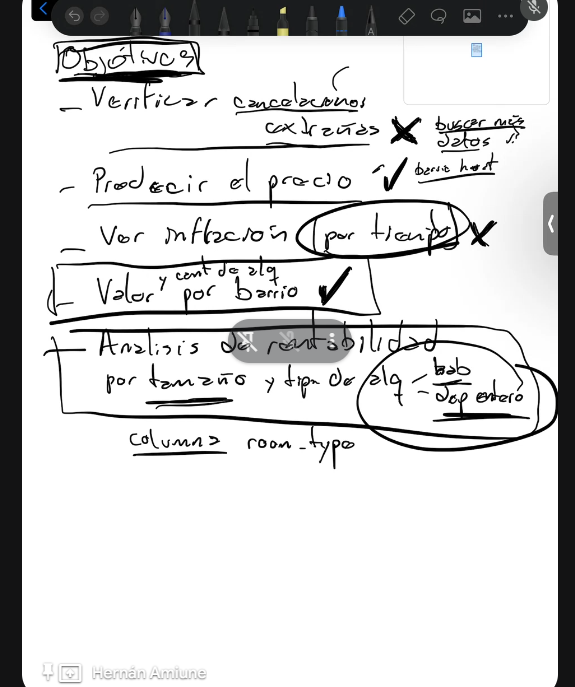

# Entregables:

- Diferencias entre precios por barrios y por tipos de apartamentos.
- Barrios más caros
- Barrios con mayor oferta de hospedajes
- Tipos de alquiler con mayor frecuencia

## Paso 6.1: Variables numéricas (visión general)

**Objetivo:** ver rangos, medias y valores raros.

```python
num_cols = df.select_dtypes(include=["int64", "float64"]).columns
df[num_cols].describe()
```

**Trucos:**

* Mirar si hay valores imposibles (edad negativa, salario 1e9, etc.).
* Ver si hay columnas casi constantes (máx ≈ mín).




## Paso 6.2: Variables numéricas (distribuciones)

**Objetivo:** ver la forma de cada variable (sesgo, cola larga, etc.).

Ejemplo con una columna:

```python
col = "edad"
df[col].hist(bins=30)
plt.xlabel(col)
plt.ylabel("Frecuencia")
plt.show()
```

**Qué ver:**

* **Simétrico**: parecido a una campana.
* **Sesgado a la derecha**: muchos valores pequeños y pocos muy grandes (típico en ingresos, tiempos, montos).
* **Sesgado a la izquierda**: al revés.

**Ideas de acciones simples:**

* Distribución muy sesgada → considerar logaritmo:
  `df["ingreso_log"] = np.log1p(df["ingreso"])`

Transformamos para que los modelos puedan entender mejor. No queremos colas extremas dominantes o escalas desproporcionadas. Aunque estas transformaciones no son necesarias para todos los modelos.




In [25]:
num_cols = df_work.select_dtypes(include=["int64", "float64"]).columns
num_cols


Index(['id', 'host_id', 'latitude', 'longitude', 'price', 'minimum_nights',
       'number_of_reviews', 'reviews_per_month',
       'calculated_host_listings_count', 'availability_365', 'has_reviews'],
      dtype='object')

In [26]:
df_work[num_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
id,48895.0,1.901714e+07,1.098311e+07,2539.00000,9.471945e+06,1.967728e+07,2.915218e+07,3.648724e+07
host_id,48895.0,6.762001e+07,7.861097e+07,2438.00000,7.822033e+06,3.079382e+07,1.074344e+08,2.743213e+08
latitude,48895.0,4.072895e+01,5.453008e-02,40.49979,4.069010e+01,4.072307e+01,4.076311e+01,4.091306e+01
longitude,48895.0,-7.395217e+01,4.615674e-02,-74.24442,-7.398307e+01,-7.395568e+01,-7.393627e+01,-7.371299e+01
price,48895.0,1.527207e+02,2.401542e+02,0.00000,6.900000e+01,1.060000e+02,1.750000e+02,1.000000e+04
minimum_nights,48895.0,7.029962e+00,2.051055e+01,1.00000,1.000000e+00,3.000000e+00,5.000000e+00,1.250000e+03
number_of_reviews,48895.0,2.327447e+01,4.455058e+01,0.00000,1.000000e+00,5.000000e+00,2.400000e+01,6.290000e+02
reviews_per_month,48895.0,1.090910e+00,1.597283e+00,0.00000,4.000000e-02,3.700000e-01,1.580000e+00,5.850000e+01
calculated_host_listings_count,48895.0,7.143982e+00,3.295252e+01,1.00000,1.000000e+00,1.000000e+00,2.000000e+00,3.270000e+02
availability_365,48895.0,1.127813e+02,1.316223e+02,0.00000,0.000000e+00,4.500000e+01,2.270000e+02,3.650000e+02


In [27]:
df_work["price"].describe()


,price
count,48895.000000
mean,152.720687
std,240.154170
min,0.000000
25%,69.000000
50%,106.000000
75%,175.000000
max,10000.000000


In [28]:
df_work["minimum_nights"].describe()


,minimum_nights
count,48895.000000
mean,7.029962
std,20.510550
min,1.000000
25%,1.000000
50%,3.000000
75%,5.000000
max,1250.000000


In [29]:
df_work["number_of_reviews"].describe()


,number_of_reviews
count,48895.000000
mean,23.274466
std,44.550582
min,0.000000
25%,1.000000
50%,5.000000
75%,24.000000
max,629.000000


In [30]:
df_work["reviews_per_month"].describe()


,reviews_per_month
count,48895.000000
mean,1.090910
std,1.597283
min,0.000000
25%,0.040000
50%,0.370000
75%,1.580000
max,58.500000


In [31]:
df_work["availability_365"].describe()


,availability_365
count,48895.000000
mean,112.781327
std,131.622289
min,0.000000
25%,0.000000
50%,45.000000
75%,227.000000
max,365.000000


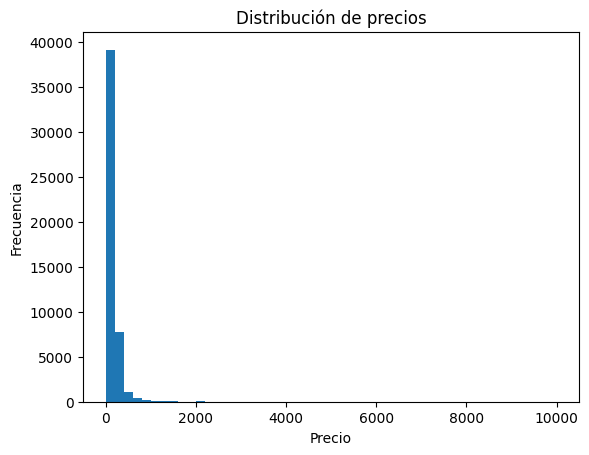

In [32]:
import matplotlib.pyplot as plt

plt.figure()
plt.hist(df_work["price"], bins=50)
plt.title("Distribución de precios")
plt.xlabel("Precio")
plt.ylabel("Frecuencia")
plt.show()


- price presenta fuerte asimetría y outliers → revisar más adelante

- minimum_nights tiene valores extremos poco realistas

- Variables de reviews tienen muchos ceros → comportamiento esperado

- No hay errores evidentes en rangos (precios negativos, noches negativas, etc.)

# Se analizaron las variables numéricas mediante estadísticas descriptivas y visualizaciones básicas para evaluar rangos, distribución y posibles valores extremos. Se identificaron variables con fuerte asimetría y outliers potenciales, anotando candidatos a transformación o tratamiento posterior.

## Paso 7.1: Variables categóricas (conteos)

**Objetivo:** ver cuántas categorías hay y cuáles son las más frecuentes.

```python
cat_cols = df.select_dtypes(include=["object", "category"]).columns

for col in cat_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts().head(10))
    print("N categorías:", df[col].nunique())
```

**Trucos:**

* Columnas con **demasiadas categorías** (ej. texto libre, IDs) → cuidado para modelos.
* Categorías muy raras → se pueden agrupar en “Otros”.




In [33]:
cat_cols = df_work.select_dtypes(include=["object", "category"]).columns
cat_cols


Index(['name', 'host_name', 'neighbourhood_group', 'neighbourhood',
       'room_type'],
      dtype='object')

In [34]:
df_work[cat_cols].nunique().sort_values(ascending=False)


,0
name,47906
host_name,11453
neighbourhood,221
neighbourhood_group,5
room_type,3


In [35]:
df_work["neighbourhood_group"].value_counts()


,count
neighbourhood_group,
Manhattan,21661
Brooklyn,20104
Queens,5666
Bronx,1091
Staten Island,373


In [36]:
df_work["room_type"].value_counts()


,count
room_type,
Entire home/apt,25409
Private room,22326
Shared room,1160


In [37]:
df_work["name"].value_counts().head(5)
df_work["host_name"].value_counts().head(5)


,count
host_name,
Michael,417
David,403
Sonder (NYC),327
John,294
Alex,279


## Paso 7.2: Variables categóricas (gráficos simples)

Ejemplo: distribución de una categoría.

```python
col = "ciudad"
df[col].value_counts().head(10).plot(kind="bar")
plt.ylabel("Cuenta")
plt.show()
```

**Qué mirar:**

* Categorías dominantes (ej. una ciudad es 90% de los casos).
* Categorías casi sin datos (quizás no valga la pena usarlas).




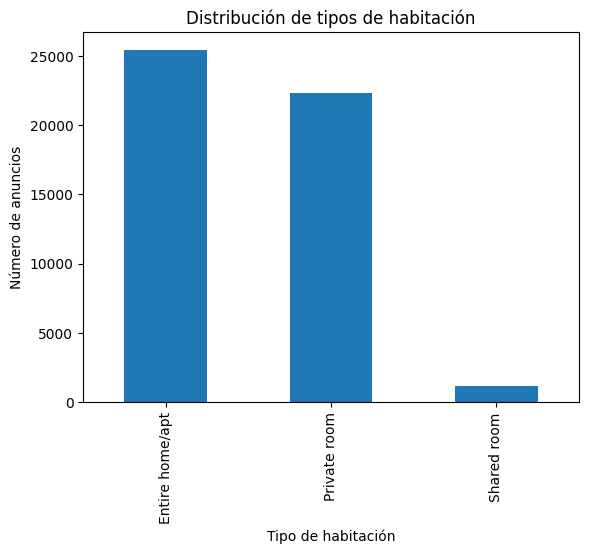

In [38]:
import matplotlib.pyplot as plt

plt.figure()
df_work["room_type"].value_counts().plot(kind="bar")
plt.title("Distribución de tipos de habitación")
plt.xlabel("Tipo de habitación")
plt.ylabel("Número de anuncios")
plt.show()


Las variables categóricas room_type y neighbourhood_group presentan una estructura clara y un alto potencial explicativo. Por el contrario, neighbourhood muestra una cardinalidad elevada que puede introducir ruido y sobreajuste en modelos de Machine Learning, por lo que requerirá tratamiento adicional o reducción.”

# Se identificaron y analizaron las variables categóricas, evaluando su cardinalidad y relevancia de negocio. Se distinguieron variables con alto poder explicativo (room_type, neighbourhood_group) de aquellas problemáticas para ML por su alta cardinalidad (neighbourhood).

## Paso 8: Fechas y tiempo

**Objetivo:** aprovechar columnas de fecha.

Asumimos que ya convertiste la columna:

```python
df["fecha"] = pd.to_datetime(df["fecha"], errors="coerce")
```

**Crear columnas derivadas fáciles:**

```python
df["anio"] = df["fecha"].dt.year
df["mes"] = df["fecha"].dt.month
df["dia_semana"] = df["fecha"].dt.day_name()
```

**Analizar evolución en el tiempo:**

```python
df_por_mes = df.groupby(["anio", "mes"])["target"].mean()  # o count
df_por_mes.plot()
plt.ylabel("Target medio")
plt.show()
```

**Nota:** ver si hay **tendencias** o **estacionalidad** (por meses, días de semana).




In [39]:
df_work["has_reviews"].value_counts(normalize=True) * 100


,proportion
has_reviews,
1,79.441661
0,20.558339


# Las variables temporales se evaluaron considerando su calidad y utilidad. En lugar de usar fechas crudas con muchos valores faltantes, se transformó la información temporal en una variable derivada (has_reviews), capturando actividad histórica de forma robusta e interpretable.


## Paso 9: Texto libre (muy básico)

**Objetivo:** tener idea de qué trae una columna de texto.

```python
df["comentario"].str.len().describe()  # longitud de texto
df["comentario"].head()
```

Trucos muy simples:

* Crear una columna con la **longitud del texto**:

  ```python
  df["len_comentario"] = df["comentario"].str.len()
  ```
* Contar cuántos están vacíos o muy cortos:

  ```python
  (df["comentario"].str.len() == 0).mean()
  ```




In [40]:
text_cols = ["name", "host_name"]
df_work[text_cols].head()


,name,host_name
0,Clean & quiet apt home by the park,John
1,Skylit Midtown Castle,Jennifer
2,THE VILLAGE OF HARLEM....NEW YORK !,Elisabeth
3,Cozy Entire Floor of Brownstone,LisaRoxanne
4,Entire Apt: Spacious Studio/Loft by central park,Laura


In [41]:
df_work[text_cols].nunique()


,0
name,47906
host_name,11453


In [42]:
df_work["name"].sample(10, random_state=0)


,name
43813,Studio in doorman building in Tribeca
32734,Large 2 bedroom downtown Loft Apartment
25276,Spacious and Modern 2 Bed/2.5 Bath Dream Townh...
36084,X 20-203
17736,Brownstone apt in Bklyn w/ gorgeous natural light
15253,"Private BR, Bed-Stuy w/backyard"
7332,Mod 3 BR duplex-East Village
40178,"Tranquil, Cozy, Comfy Cottage."
48175,Very Large/Spacious Private Bedroom in Manhattan
14403,Private Room in Uptown Manhattan


In [43]:
df_work["host_name"].sample(10, random_state=0)


,host_name
43813,Jonas
32734,Zinnia
25276,Tasha
36084,Shimin
17736,Whitney
15253,Nicholas
7332,Cara
40178,Julie
48175,Jona
14403,Hannah


Decisión del Paso 9

- Excluir name y host_name como variables predictoras

- Mantenerlas fuera del dataset de modelado

- Documentar explícitamente el motivo

Importante: no es porque “no se pueda”, sino porque:

- el coste de procesamiento es alto

- el beneficio esperado aquí es bajo

In [44]:
df_work["name"] = df_work["name"].str.strip()
df_work["host_name"] = df_work["host_name"].str.strip()


# Las variables de texto libre (name, host_name) presentan alta cardinalidad y ausencia de estructura semántica controlada. Dado el objetivo del análisis y para evitar introducir ruido y complejidad innecesaria, se decidió no utilizarlas como variables predictoras en modelos de Machine Learning, reservando su uso únicamente para análisis exploratorio o proyectos específicos de NLP.

# Objetivos actuales


- Diferencias de precios por barrio y tipo de alojamiento

- Barrios más caros

- Barrios con mayor oferta de hospedajes

- Tipos de alquiler con mayor frecuencia

Estos cubren precio, oferta y tipología, que son ejes centrales del mercado.

# Objetivos adicionales que ancajan con los objetivos principales:

- Relación entre el precio y disponibilidad ¿Los alojamientos más caros están más o menos disponibles?  
EDA:
  * price vs availability_365
  * Barrios con mucha oferta pero baja disponibilidad
Insight clave:
  * Precios altos + baja disponibilidad -> zonas premium
  * Precios bajos + alta disponibilidad -> exceso de oferta

- Relación entre precio y tipo de habitación ¿La diferencia de precio entre "entire home" y "private room" es constante en todos los barrios?
EDA:
  * price por room_type dentro de cada barrio
  * Comparaciones relativas, no solo absolutas

- Concentración de oferta por barrio ¿La oferta está distribuida entre muchos hosts o concentrada en pocos? (No solo "cuántos", sino quién concentra)
EDA:
  * Número de anuncios por host_id en cada barrio
  * Hosts profesionales vs particulares

Insight clave:
  * Barrios con concentración → mercado más profesionalizado

- Impacto de la actividad (reviews) en el precio (Conecta con has_reviews) ¿Los anuncios con reviews son más caros que los que no tienen?
EDA:
  * price vs has_reviews
  * Comparaciones por barrio y tipo de habitación

Insight típico:
  * Reviews = confianza = precio más alto

- Relación entre precio y demanda (proxy) - EDA, no causalidad -  ¿Los anuncios con más reviews tienden a tener precios distintos?
EDA:
  * price vs number_of_reviews
  * price vs reviews_per_month

Insights clave
  * elasticidad aparente
  * segmentos de mercado

- Barrios con más anuncios “nuevos” (Dinámica del mercado) ¿En qué barrios hay más anuncios sin reviews?
EDA:
  * has_reviews == 0 por barrio

Indica:
  * barrios en expansión
  * nuevas oportunidades de mercado

- Tipos de alojamiento por barrio (Perfil del barrio) ¿Qué tipo de alojamiento domina en cada barrio?
EDA:
  * Distribución de room_type por neighbourhood_group

Insight:
  * barrios turísticos vs residenciales

- Precio vs reglas del alojamiento (Regulación implícita) ¿Los alojamientos con estancias mínimas largas son más caros?
EDA:
  * price vs minimum_nights

Muy útil para entender:
  * alquiler turístico vs “larga estancia disfrazada”

# BLOQUES DE OBJETIVOS

🔹 BLOQUE A — Precio

- Diferencias de precio por barrio

- Precio por tipo de alojamiento

- Barrios más caros

🔹 BLOQUE B — Oferta

- Barrios con más anuncios

- Concentración de hosts

- Tipos de alojamiento más frecuentes

🔹 BLOQUE C — Demanda / actividad (proxy)

- Reviews y precio

- Disponibilidad

- Anuncios nuevos vs consolidados

🔹 BLOQUE D — Perfil del barrio

- Mix de tipos de alojamiento

- Profesionalización del mercado

## Paso 10: Relación con la variable objetivo (clasificación)

### 10.1. Numérica vs target binario (0/1)

**Objetivo:** ver si la variable ayuda a separar clases.

```python
col = "edad"
df.groupby("target")[col].describe()
```

**Explicación simple:**
Comparar la media de `edad` para target=0 y target=1.
Si son muy diferentes, esa variable probablemente sea útil.



### 10.2. Categoría vs target binario

```python
col = "ciudad"
tabla = (
    df.groupby(col)["target"]
      .mean()
      .sort_values(ascending=False)
      .head(10)
)
print(tabla)
```

**Qué mirar:**
Ciudades con tasa de target mucho más alta o más baja → categorías importantes.





# Entender price como variable central

In [45]:
df_work["price"].describe()


,price
count,48895.000000
mean,152.720687
std,240.154170
min,0.000000
25%,69.000000
50%,106.000000
75%,175.000000
max,10000.000000


Lectura clave:

- price es asimétrica

- hay outliers

- la mediana es más representativa que la media

A partir de ahora, usaremos medianas más que medias cuando tenga sentido.

# Precio por tipo de alojamiento (room_type)
Pregunta de negocio

¿Cuánto cambia el precio según el tipo de alojamiento?

In [46]:
df_work.groupby("room_type")["price"].median().sort_values()


,price
room_type,
Shared room,45.0
Private room,70.0
Entire home/apt,160.0


<Figure size 640x480 with 0 Axes>

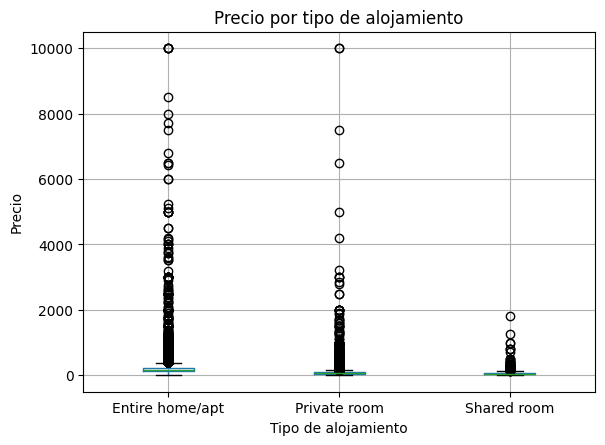

In [47]:
import matplotlib.pyplot as plt

plt.figure()
df_work.boxplot(column="price", by="room_type")
plt.title("Precio por tipo de alojamiento")
plt.suptitle("")
plt.xlabel("Tipo de alojamiento")
plt.ylabel("Precio")
plt.show()


Interpretación esperada

- Entire home/apt → más caro

- Private room → intermedio

- Shared room → más barato

Relación fuerte y clara → variable clave.

# Precio por barrio macro (neighbourhood_group)
Pregunta de negocio

¿Qué barrios son más caros?

In [48]:
df_work.groupby("neighbourhood_group")["price"].median().sort_values(ascending=False)


,price
neighbourhood_group,
Manhattan,150.0
Brooklyn,90.0
Queens,75.0
Staten Island,75.0
Bronx,65.0


<Figure size 640x480 with 0 Axes>

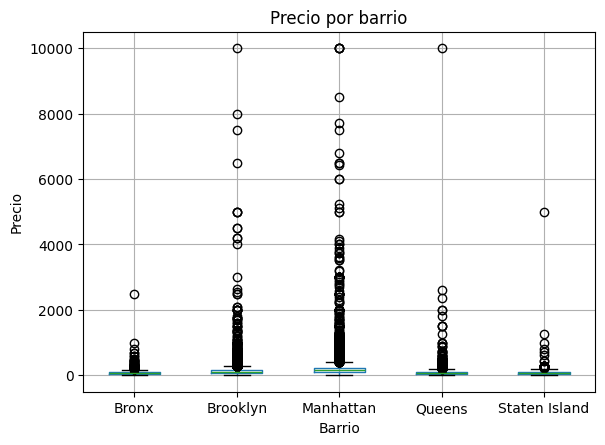

In [49]:
plt.figure()
df_work.boxplot(column="price", by="neighbourhood_group")
plt.title("Precio por barrio")
plt.suptitle("")
plt.xlabel("Barrio")
plt.ylabel("Precio")
plt.show()


Interpretación típica

- Manhattan arriba

- Brooklyn segundo

- Bronx / Staten Island abajo

Insight urbano directo.

# Precio vs actividad (reviews)
has_reviews

In [50]:
df_work.groupby("has_reviews")["price"].median()


,price
has_reviews,
0,120.0
1,101.0


Interpretación:

- Los anuncios SIN reviews son más caros en mediana.

Varias razones reales:

- Anuncios nuevos de gama alta

- Hosts que ponen precios altos antes de tener reviews

- Viviendas de lujo con poca rotación


“Los anuncios sin reviews presentan una mediana de precio superior, lo que sugiere que parte de la oferta premium corresponde a anuncios nuevos o con baja rotación.”


number_of_reviews

In [51]:
df_work[["price", "number_of_reviews"]].corr()


,price,number_of_reviews
price,1.000000,-0.047954
number_of_reviews,-0.047954,1.000000


Correlación baja o moderada ≠ irrelevante


Indica relación no lineal o por segmentos. (ej. baratos con muchas reviews, caros con pocas)

# Precio vs disponibilidad (availability_365)
Pregunta

¿Los alojamientos más caros están más o menos disponibles?

In [52]:
df_work[["price", "availability_365"]].corr()


,price,availability_365
price,1.000000,0.081829
availability_365,0.081829,1.000000


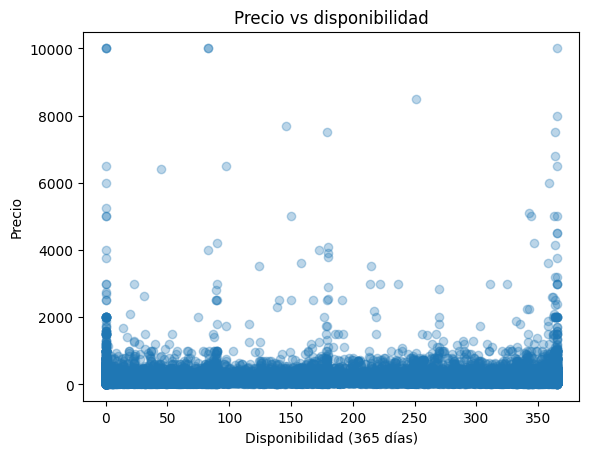

In [53]:
plt.figure()
plt.scatter(df_work["availability_365"], df_work["price"], alpha=0.3)
plt.xlabel("Disponibilidad (365 días)")
plt.ylabel("Precio")
plt.title("Precio vs disponibilidad")
plt.show()


precios altos concentrados en menor disponibilidad

precios bajos con mayor disponibilidad

# Precio vs reglas (minimum_nights)

In [54]:
df_work.groupby("minimum_nights")["price"].median().head(10)


,price
minimum_nights,
1,90.0
2,110.0
3,122.0
4,125.0
5,120.0
6,120.0
7,100.0
8,99.5
9,109.5


Interpretación:

- Reglas más estrictas → precios más altos

- A partir de cierto punto, ya no escala linealmente

Esto sugiere:

- alquileres de media/larga estancia

- regulación implícita

# CONCLUSIÓN GENERAL

- room_type y neighbourhood_group son drivers claros del precio

- El precio no se explica por una sola variable

- Muchas relaciones son segmentadas y no lineales

- El EDA está coherente con el dominio real


## Paso 11: Correlaciones (numéricas)

**Objetivo:** ver qué variables numéricas se parecen (se mueven juntas).

```python
corr = df[num_cols].corr()
corr["target"].sort_values(ascending=False)
```

**Que significa:**

* Correlación cerca de **1**: suben y bajan juntas.
* Cerca de **-1**: una sube cuando la otra baja.
* Cerca de **0**: no hay relación lineal clara.

También ver **correlaciones entre variables predictoras**:

* Si dos columnas están casi perfectamente correlacionadas → quizás una sobra.




In [55]:
num_cols = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365",
    "latitude",
    "longitude",
    "has_reviews"
]

In [56]:
corr_matrix = df_work[num_cols].corr()
corr_matrix


,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,latitude,longitude,has_reviews
price,1.000000,0.042799,-0.047954,-0.050564,0.057472,0.081829,0.033939,-0.150019,-0.085151
minimum_nights,0.042799,1.000000,-0.080116,-0.124905,0.127960,0.144303,0.024869,-0.062747,-0.111360
number_of_reviews,-0.047954,-0.080116,1.000000,0.589407,-0.072376,0.172028,-0.015389,0.059094,0.265767
reviews_per_month,-0.050564,-0.124905,0.589407,1.000000,-0.047312,0.163732,-0.018758,0.138516,0.347441
calculated_host_listings_count,0.057472,0.127960,-0.072376,-0.047312,1.000000,0.225701,0.019517,-0.114713,-0.118088
availability_365,0.081829,0.144303,0.172028,0.163732,0.225701,1.000000,-0.010983,0.082731,0.031387
latitude,0.033939,0.024869,-0.015389,-0.018758,0.019517,-0.010983,1.000000,0.084788,-0.029387
longitude,-0.150019,-0.062747,0.059094,0.138516,-0.114713,0.082731,0.084788,1.000000,0.043506
has_reviews,-0.085151,-0.111360,0.265767,0.347441,-0.118088,0.031387,-0.029387,0.043506,1.000000


In [57]:
corr_with_price = corr_matrix["price"].sort_values(ascending=False)
corr_with_price


,price
price,1.000000
availability_365,0.081829
calculated_host_listings_count,0.057472
minimum_nights,0.042799
latitude,0.033939
number_of_reviews,-0.047954
reviews_per_month,-0.050564
has_reviews,-0.085151
longitude,-0.150019


* Correlaciones bajas a moderadas

* Ninguna variable numérica explica price por sí sola


El precio es una variable multifactorial, no lineal.

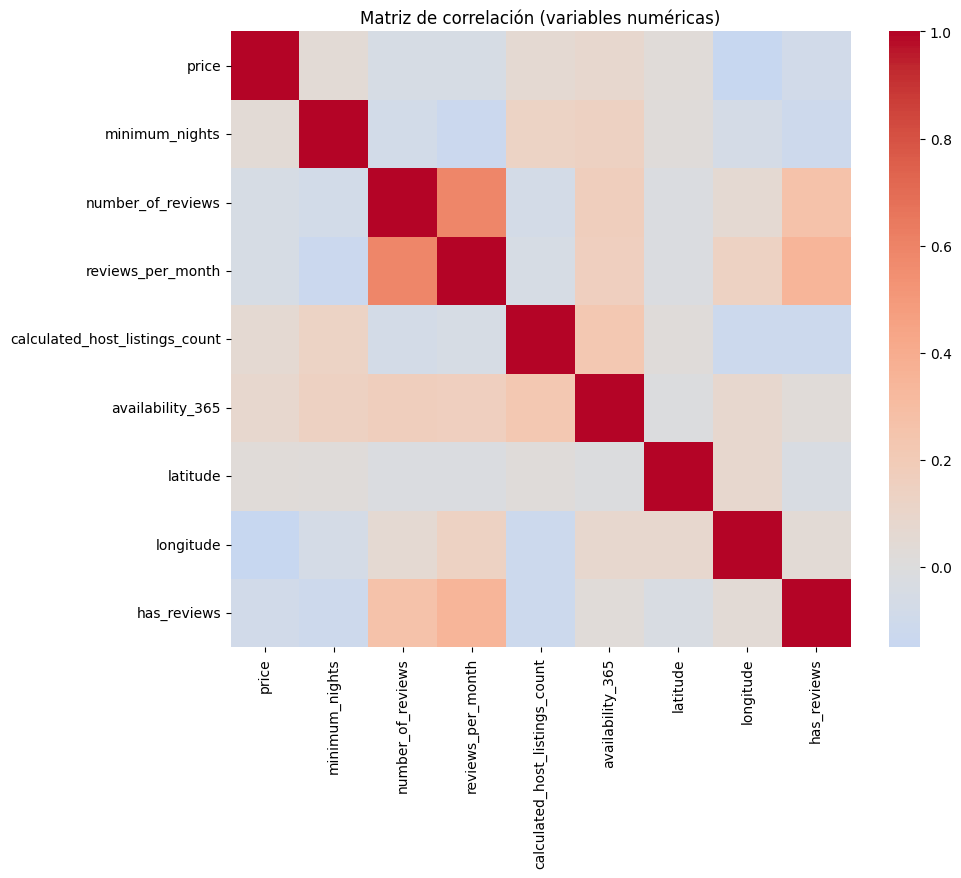

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=False, cmap="coolwarm", center=0)
plt.title("Matriz de correlación (variables numéricas)")
plt.show()


In [59]:
corr_matrix.loc[
    ["number_of_reviews", "reviews_per_month", "has_reviews"],
    ["number_of_reviews", "reviews_per_month", "has_reviews"]
]


,number_of_reviews,reviews_per_month,has_reviews
number_of_reviews,1.000000,0.589407,0.265767
reviews_per_month,0.589407,1.000000,0.347441
has_reviews,0.265767,0.347441,1.000000


- number_of_reviews ↔ reviews_per_month
    → correlación alta esperada

- has_reviews correlaciona con ambas (derivada lógica)

In [60]:
corr_matrix.loc[["price"], ["latitude", "longitude"]]


,latitude,longitude
price,0.033939,-0.150019


Interpretación

- Correlación lineal baja

- No significa que la ubicación no importe

Ubicación actúa:

- de forma no lineal

- por zonas

- ya capturada mejor por neighbourhood_group

Las correlaciones lineales entre variables numéricas y el precio son en general bajas, lo que indica que el precio está influido por múltiples factores y relaciones no lineales. Se detecta multicolinealidad esperada entre variables de actividad (number_of_reviews, reviews_per_month, has_reviews), derivada de su naturaleza semántica común. No se observan problemas críticos de redundancia que afecten al análisis exploratorio.

## Paso 12: Outliers (valores extremos)

### 12.1. Por regla simple

```python
col = "ingreso"
df[col].describe()
```

Luego:

```python
# Filas con valores muy grandes
df[df[col] > df[col].quantile(0.99)].head()
```

### 12.2. Boxplot simple

```python
df[[col]].boxplot()
plt.show()
```

**Nota:**

* Un outlier no siempre es un error.
* Preguntar: ¿es un error de carga o un cliente realmente enorme?
* Opciones simples: recortar (cap), transformar (log), o dejarlos pero avisar al modelo.




In [61]:
df_work["price"].describe()


,price
count,48895.000000
mean,152.720687
std,240.154170
min,0.000000
25%,69.000000
50%,106.000000
75%,175.000000
max,10000.000000


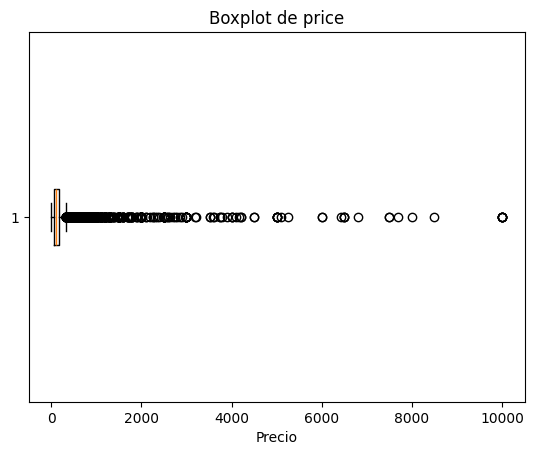

In [62]:
import matplotlib.pyplot as plt

plt.figure()
plt.boxplot(df_work["price"], vert=False)
plt.title("Boxplot de price")
plt.xlabel("Precio")
plt.show()


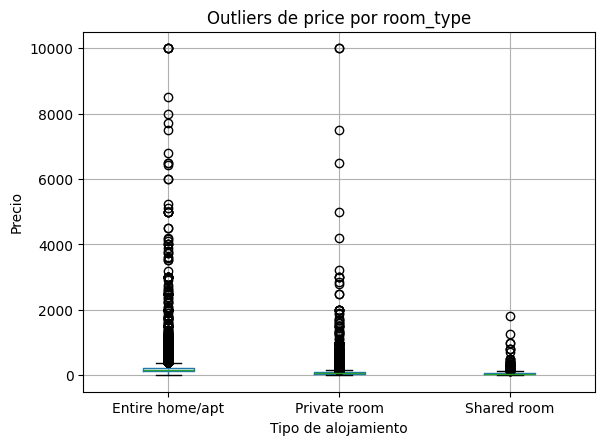

In [63]:
df_work.boxplot(column="price", by="room_type")
plt.suptitle("")
plt.title("Outliers de price por room_type")
plt.xlabel("Tipo de alojamiento")
plt.ylabel("Precio")
plt.show()


- Entire home/apt concentra los outliers altos

- Shared room casi no tiene extremos

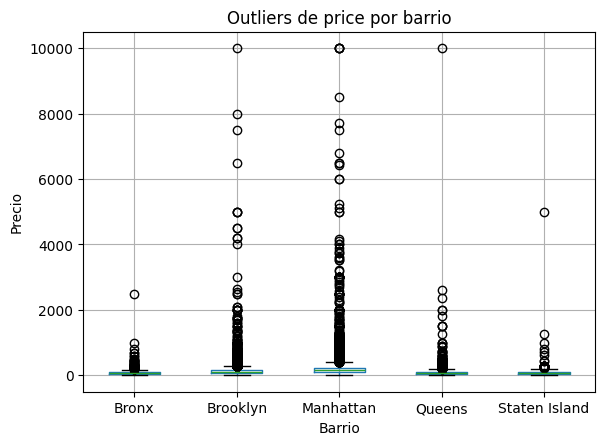

In [64]:
df_work.boxplot(column="price", by="neighbourhood_group")
plt.suptitle("")
plt.title("Outliers de price por barrio")
plt.xlabel("Barrio")
plt.ylabel("Precio")
plt.show()


- Manhattan concentra precios extremos

- Bronx y Staten Island casi no

In [65]:
(df_work["price"] == 0).sum()


np.int64(11)

In [66]:
df_work["minimum_nights"].describe()


,minimum_nights
count,48895.000000
mean,7.029962
std,20.510550
min,1.000000
25%,1.000000
50%,3.000000
75%,5.000000
max,1250.000000


In [67]:
df_work["availability_365"].value_counts().head()
df_work["availability_365"].value_counts().tail()


,count
availability_365,
195,26
183,24
196,24
181,23
202,20


Qué NO considerar outlier (importante)

- Precios altos en Manhattan → válidos
- Hosts con muchos anuncios → válidos
- Muchos reviews → válidos

EDA ≠ eliminar todo lo raro.


- price = 0 → revisar o excluir en análisis/modelado

- Precios > percentil 99 → considerar capado según objetivo

- minimum_nights extremos → segmentar o excluir si se analiza turismo puro

- Mantener outliers explicables por negocio

Se identificaron valores extremos principalmente en la variable price, con una fuerte asimetría a la derecha y presencia de precios muy elevados, especialmente en alojamientos completos y en Manhattan. Estos outliers se consideran mayoritariamente coherentes con el negocio. No obstante, se detectaron valores raros como price = 0 y valores extremos en minimum_nights, que se anotan como candidatos a tratamiento específico en etapas posteriores.

## Paso 13.1: Columnas inútiles o sospechosas

**Checklist simple:**

* Columnas **idénticas** o muy similares entre sí.
* Columnas con **un solo valor** (sin variabilidad).
* IDs puros (no explican nada, solo identifican).
* Columnas que se conocen **después** del resultado (leakage).

Código rápido:

```python
# columnas casi constantes
n = len(df)
for col in df.columns:
    freq = df[col].value_counts(normalize=True, dropna=False).iloc[0]
    if freq > 0.99:
        print("Casi constante:", col, f"({freq:.2%} mismo valor)")
```




## Paso 13.2: Data leakage (explicación simple)

**Objetivo:** evitar “hacer trampa”.

**Ejemplos:**

* Predecir si un cliente dejará la empresa usando una columna “fecha_de_baja”.
* Predecir ventas del mes usando la columna “ventas_del_mes” 🤦.

**Regla de oro:**

> Si la columna no estaría disponible en el momento real de hacer la predicción, no puede usarse.




Se revisaron las variables desde la perspectiva de data leakage. Se identificó que las variables relacionadas con actividad (number_of_reviews, reviews_per_month, has_reviews) solo serían válidas si el precio se predice con el anuncio ya activo. En un escenario de predicción de precios iniciales, estas variables introducirían data leakage y deberían excluirse

## Paso 14: Crear reporte y/o pipeline

Anotar conclusiones y decisiones (drop, imputar, transformar, etc.) para poder replicar en otros datasets (train, test o actualizaciones) o experimentos.

- Dataset base

Airbnb NYC 2019

- Limpieza

Eliminar duplicados exactos → ninguno encontrado

Tratar valores faltantes:

    * last_review → eliminado

    * reviews_per_month → imputado con 0

    * creación de has_reviews

- Transformaciones

Usar mediana para análisis de price

No transformar price aún (solo anotado)

Mantener outliers explicables por negocio

- Variables excluidas

name, host_name → texto libre

neighbourhood → alta cardinalidad (pendiente de agrupación)

- Riesgos identificados

Outliers extremos en price

Potencial data leakage en variables de reviews según escenario

Las decisiones de limpieza, imputación y selección de variables fueron documentadas con el objetivo de construir un pipeline replicable y consistente, facilitando la reutilización del proceso en nuevos datasets o escenarios de modelado

Dataset: Airbnb NYC 2019
________________________________________
1️⃣ Calidad general del dataset
El dataset presenta una buena calidad estructural para análisis exploratorio y posterior modelado:
•	No existen duplicados exactos.
•	Los valores faltantes identificados tienen significado de negocio y fueron tratados de forma coherente.
•	No se detectaron incoherencias graves en rangos numéricos (valores negativos imposibles, fechas corruptas, etc.).
👉 El dataset es apto para EDA avanzado y preparación para ML, con decisiones bien documentadas.
________________________________________
2️⃣ Precio (price) como variable central
El precio presenta una distribución fuertemente asimétrica a la derecha, con:
•	Mediana significativamente inferior a la media.
•	Presencia de outliers elevados (hasta 10.000).
•	Valores raros como price = 0, que no tienen sentido económico.
📌 Conclusión clave:
La mediana es una medida más representativa que la media para análisis descriptivos de precio.
El precio no se explica por una única variable, sino por la combinación de múltiples factores.
________________________________________
3️⃣ Variables más relevantes para explicar el precio
🔹 Variables categóricas clave
•	room_type: principal driver del precio.
o	Entire home/apt → significativamente más caro
o	Private room → intermedio
o	Shared room → más barato
•	neighbourhood_group: fuerte componente geográfico.
o	Manhattan es el barrio más caro.
o	Bronx y Staten Island presentan los precios más bajos.
👉 Ambas variables muestran relaciones claras, estables y coherentes con el negocio.
________________________________________
4️⃣ Oferta y estructura del mercado
•	La oferta no está distribuida homogéneamente:
o	Existen hosts con gran concentración de anuncios, lo que indica profesionalización del mercado en ciertas zonas.
•	Las repeticiones por host o ubicación no son errores, sino patrones reales del negocio.
📌 Insight:
Algunos barrios presentan mercados más profesionalizados que otros, lo que puede influir en precios y disponibilidad.
________________________________________
5️⃣ Actividad, demanda y disponibilidad (variables proxy)
•	Las variables de reviews (has_reviews, number_of_reviews, reviews_per_month) muestran:
o	Alta multicolinealidad esperada.
o	Relaciones no lineales con el precio.
Resultado clave:
•	Los anuncios sin reviews presentan una mediana de precio superior, lo que sugiere presencia de anuncios nuevos o de gama alta con baja rotación.
•	La disponibilidad (availability_365) muestra un patrón claro:
o	Precios altos → menor disponibilidad
o	Precios bajos → mayor disponibilidad
📌 Esto refleja dinámicas reales de oferta y demanda, aunque no lineales.
________________________________________
6️⃣ Outliers y valores raros
•	Los outliers de precio se concentran principalmente en:
o	Entire home/apt
o	Manhattan
👉 Se consideran coherentes con el negocio.
•	Valores como price = 0 y minimum_nights extremadamente altos:
o	No representan el mercado turístico estándar.
o	Se anotan como candidatos a tratamiento específico según el objetivo final (ML, reporting, segmentación).
________________________________________
7️⃣ Variables descartadas o tratadas con cautela
•	Texto libre (name, host_name):
o	Alta cardinalidad.
o	Baja estructura.
o	No se utilizan como features directas.
•	neighbourhood:
o	Alta cardinalidad.
o	Potencial informativo, pero problemática para ML sin agrupación previa.
________________________________________
8️⃣ Conclusión global del EDA
El análisis exploratorio revela que el precio de los alojamientos en Airbnb NYC está determinado por una combinación de factores estructurales (tipo de alojamiento, barrio), dinámicos (disponibilidad, actividad) y regulatorios implícitos (noches mínimas). Las relaciones observadas son mayoritariamente no lineales y segmentadas, lo que refuerza la necesidad de un enfoque cuidadoso en la preparación de datos para modelado o reporting avanzado.


# Escenario elegido (explícito)

Predecir el precio de un anuncio ya activo en Airbnb

Esto implica que:

✔️ podemos usar variables de actividad (reviews)

❌ no estamos prediciendo “precio inicial”

Variable objetivo (y)

In [68]:
y = df_work["price"]


# Selección de features

Variables que SÍ incluimos

🔹 Numéricas

- minimum_nights

- number_of_reviews

- reviews_per_month

- availability_365

- calculated_host_listings_count

- latitude

- longitude

- has_reviews

🔹 Categóricas

- room_type

- neighbourhood_group


Variables que excluimos y por qué

| Variable            | Motivo            |
| ------------------- | ----------------- |
| `price`             | target            |
| `id`, `host_id`     | identificadores   |
| `name`, `host_name` | texto libre       |
| `neighbourhood`     | alta cardinalidad |
| `last_review`       | ya transformada   |


In [69]:
feature_cols = [
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "availability_365",
    "calculated_host_listings_count",
    "latitude",
    "longitude",
    "has_reviews",
    "room_type",
    "neighbourhood_group"
]

X = df_work[feature_cols].copy()


In [70]:
X = pd.get_dummies(
    X,
    columns=["room_type", "neighbourhood_group"],
    drop_first=True
)


In [71]:
X.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   minimum_nights                     48895 non-null  int64  
 1   number_of_reviews                  48895 non-null  int64  
 2   reviews_per_month                  48895 non-null  float64
 3   availability_365                   48895 non-null  int64  
 4   calculated_host_listings_count     48895 non-null  int64  
 5   latitude                           48895 non-null  float64
 6   longitude                          48895 non-null  float64
 7   has_reviews                        48895 non-null  int64  
 8   room_type_Private room             48895 non-null  bool   
 9   room_type_Shared room              48895 non-null  bool   
 10  neighbourhood_group_Brooklyn       48895 non-null  bool   
 11  neighbourhood_group_Manhattan      48895 non-null  boo

In [72]:
X.isnull().sum().sum()


np.int64(0)

In [73]:
y = df_work["price"]
X = df_work.drop(columns=["price"])

X.shape, y.shape


((48895, 15), (48895,))

In [74]:
X_encoded = pd.get_dummies(X, drop_first=True)
X_encoded.shape


(48895, 59582)

In [75]:
print("Nulos totales en X:", X_encoded.isnull().sum().sum())
print("Tipos no numéricos:", (X_encoded.dtypes == "object").sum())


Nulos totales en X: 0
Tipos no numéricos: 0


In [76]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42
)

X_train.shape, X_test.shape, y_train.shape, y_test.shape


((39116, 59582), (9779, 59582), (39116,), (9779,))

In [ ]:
import pandas as pd
import numpy as np

# --- Re-creating df and df_work for independent execution ---
df = pd.read_csv("https://raw.githubusercontent.com/4GeeksAcademy/data-preprocessing-project-tutorial/main/AB_NYC_2019.csv")
df_work = df.copy()

df_work["reviews_per_month"] = df_work["reviews_per_month"].fillna(0)
df_work["has_reviews"] = df_work["last_review"].notna().astype(int)
df_work = df_work.drop(columns=["last_review"])
df_work["host_name"] = df_work["host_name"].fillna("Unknown")
df_work["name"] = df_work["name"].fillna("Unknown")
df_work["name"] = df_work["name"].str.strip()
df_work["host_name"] = df_work["host_name"].str.strip()
# --- End of df_work re-creation ---

y = df_work["price"]
X = df_work.drop(columns=["price"])
X_encoded = pd.get_dummies(X, drop_first=True)

df_processed = pd.concat([y, X_encoded], axis=1)
df_processed.to_csv("AB_NYC_2019_processed.csv", index=False)

df_processed.shape

El escalado de variables numéricas se aplicará en función del modelo seleccionado, utilizando pipelines para evitar data leakage.

In [2]:
import pandas as pd
import numpy as np

# Re-creating df and df_work for independent execution
df = pd.read_csv("https://raw.githubusercontent.com/4GeeksAcademy/data-preprocessing-project-tutorial/main/AB_NYC_2019.csv")
df_work = df.copy()

df_work["reviews_per_month"] = df_work["reviews_per_month"].fillna(0)
df_work["has_reviews"] = df_work["last_review"].notna().astype(int)
df_work = df_work.drop(columns=["last_review"])
df_work["host_name"] = df_work["host_name"].fillna("Unknown")
df_work["name"] = df_work["name"].fillna("Unknown")
df_work["name"] = df_work["name"].str.strip()
df_work["host_name"] = df_work["host_name"].str.strip()

df_dash = df_work.copy()

# Visual 1 — Precio por tipo de alojamiento
Pregunta de negocio

¿Qué tipo de alojamiento es más caro?

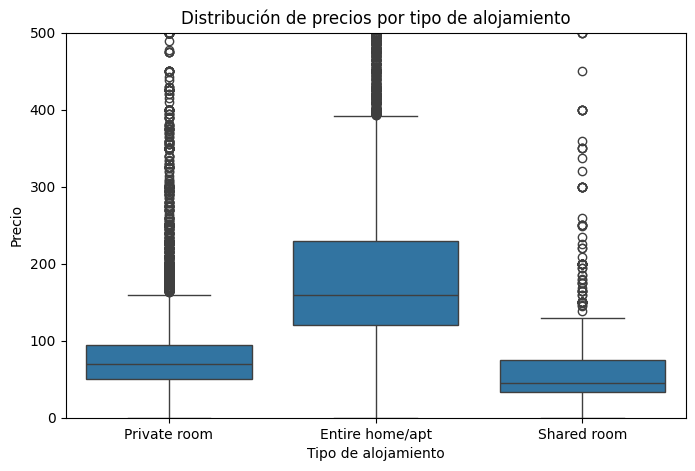

In [5]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df_dash,
    x="room_type",
    y="price"
)
plt.title("Distribución de precios por tipo de alojamiento")
plt.xlabel("Tipo de alojamiento")
plt.ylabel("Precio")
plt.ylim(0, 500)  # recorte visual para evitar distorsión
plt.show()


# Visual 2 — Precio por barrio (macro)

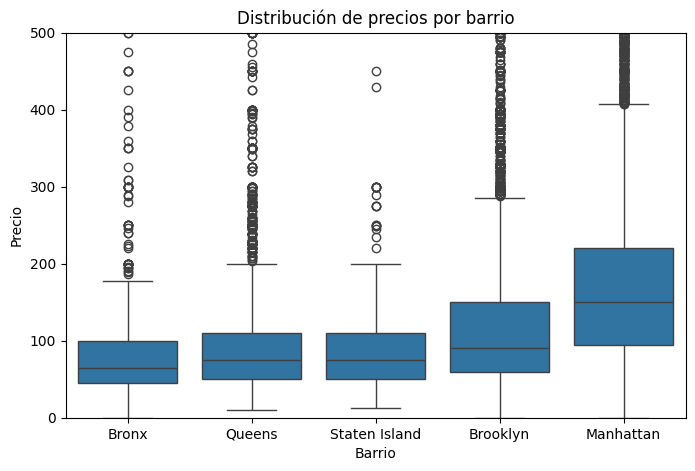

In [6]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df_dash,
    x="neighbourhood_group",
    y="price",
    order=df_dash.groupby("neighbourhood_group")["price"].median().sort_values().index
)
plt.title("Distribución de precios por barrio")
plt.xlabel("Barrio")
plt.ylabel("Precio")
plt.ylim(0, 500)
plt.show()


# Visual 3 — Oferta por barrio (volumen)
Pregunta

¿Dónde hay más alojamientos?

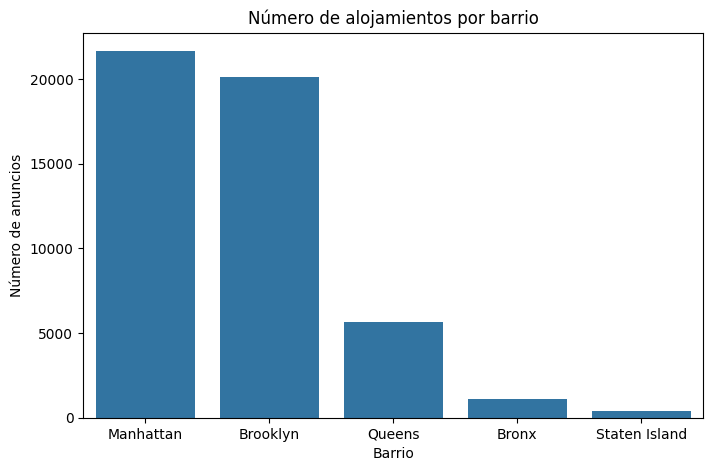

In [7]:
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df_dash,
    x="neighbourhood_group",
    order=df_dash["neighbourhood_group"].value_counts().index
)
plt.title("Número de alojamientos por barrio")
plt.xlabel("Barrio")
plt.ylabel("Número de anuncios")
plt.show()


# Visual 5 — Relación precio vs disponibilidad

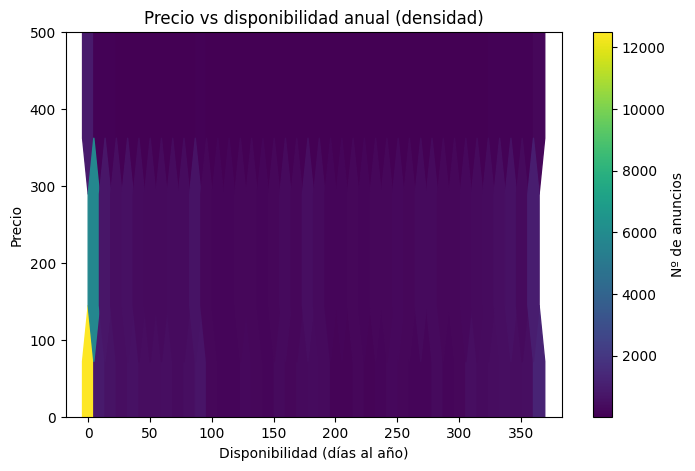

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hexbin(
    df_dash["availability_365"],
    df_dash["price"],
    gridsize=40,   # tamaño de celdas (más = más detalle)
    mincnt=1       # muestra solo celdas con datos
)
plt.title("Precio vs disponibilidad anual (densidad)")
plt.xlabel("Disponibilidad (días al año)")
plt.ylabel("Precio")
plt.ylim(0, 500)
plt.colorbar(label="Nº de anuncios")
plt.show()


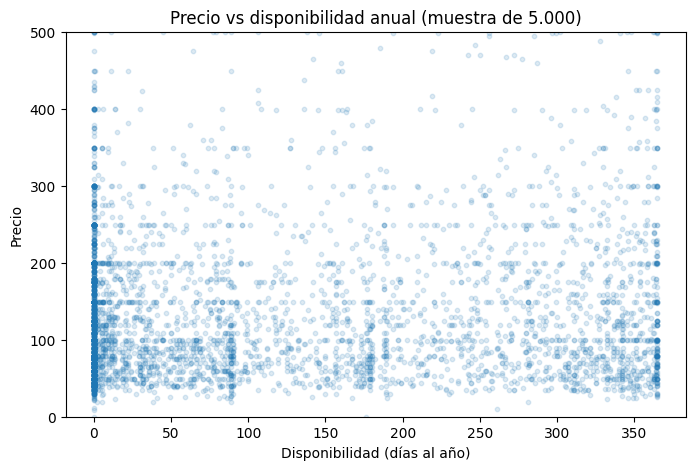

In [9]:
import matplotlib.pyplot as plt

sample = df_dash.sample(5000, random_state=0)  # ajusta 5000 si quieres más/menos

plt.figure(figsize=(8, 5))
plt.scatter(
    sample["availability_365"],
    sample["price"],
    alpha=0.15,
    s=10
)
plt.title("Precio vs disponibilidad anual (muestra de 5.000)")
plt.xlabel("Disponibilidad (días al año)")
plt.ylabel("Precio")
plt.ylim(0, 500)
plt.show()


/tmp/ipython-input-2962246337.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  summary = tmp.groupby("avail_bin")["price"].median()


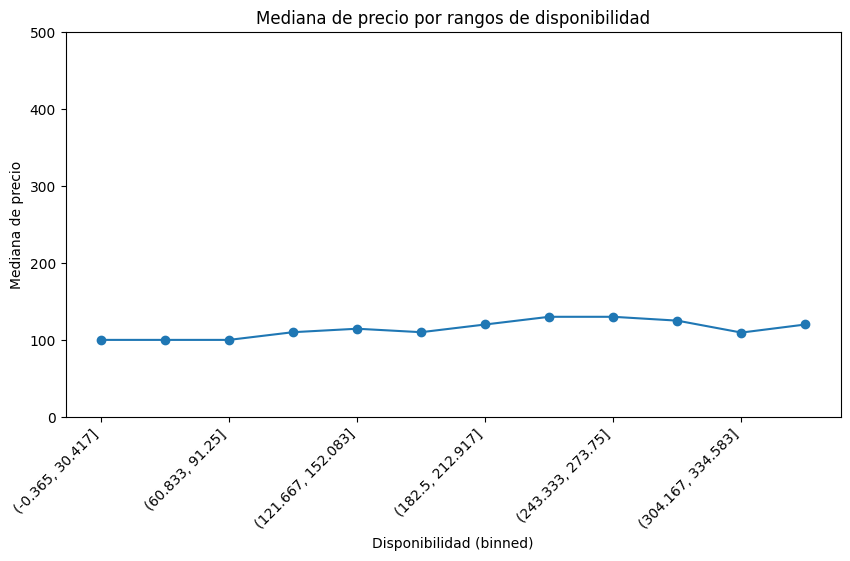

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

tmp = df_dash[["availability_365", "price"]].copy()

# Crear bins (grupos) de disponibilidad
tmp["avail_bin"] = pd.cut(tmp["availability_365"], bins=12)

# Mediana de precio por bin
summary = tmp.groupby("avail_bin")["price"].median()

plt.figure(figsize=(10, 5))
summary.plot(kind="line", marker="o")
plt.title("Mediana de precio por rangos de disponibilidad")
plt.xlabel("Disponibilidad (binned)")
plt.ylabel("Mediana de precio")
plt.ylim(0, 500)
plt.xticks(rotation=45, ha="right")
plt.show()


## Paso 15 (bonus): Reporte rápido automático

- [sweetviz](https://colab.research.google.com/github/amiune/freecodingtour/blob/main/cursos/espanol/datascience/analysis/A1.2_eda_sweetviz.ipynb)
- [pandas_dq](https://colab.research.google.com/github/amiune/freecodingtour/blob/main/cursos/espanol/datascience/analysis/A3.3_pandas_dq.ipynb)
-[mas...](https://colab.research.google.com/github/amiune/freecodingtour/blob/main/cursos/espanol/datascience/analysis/A0_intro.ipynb#scrollTo=48149491-163e-4f79-a52a-91e027f85bf5)

# Paso 16 (extra bonus): Ver distintos analisis en kaggle

- https://www.kaggle.com/datasets/saritas95/nyc-airbnb-insights-a-data-analysis
- https://www.kaggle.com/code/phongphmlm/airbnb-new-york-city-2019
- https://www.kaggle.com/code/dgomonov/data-exploration-on-nyc-airbnb
- https://www.kaggle.com/code/chbenitez/airbnb-nyc-an-lisis-y-preprocesamiento-de-datos/notebook
- https://www.kaggle.com/code/duygut/airbnb-nyc-price-prediction